# TUSZ external seizure-onset detection: final Results analysis

This notebook analyzes the final fixed-regime TUSZ external seizure-onset detection experiment.

Final analysis structure:
- 63 eligible TUSZ patients;
- fixed Rössler regime R4;
- five reservoir realizations per patient;
- 30-s seizure-onset test windows;
- 3-s persistence as the primary operating point;
- 5-s persistence retained as an operating-point comparison;
- patient-level performance summarized across reservoir realizations.

Because the external cohort contains 63 patients, patient-wise manuscript figures are split into three ordered panels to preserve readability while retaining the same visual convention used for CHB--MIT.


In [2]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.max_columns', 200)
pd.set_option('display.max_rows', 200)
pd.set_option('display.width', 180)

RESULT_ROOT = Path('tusz_ictal_rossler_bd_v4_results')
ANALYSIS_DIR = Path('tusz_ictal_rossler_bd_v4_analysis')
FIG_DIR = ANALYSIS_DIR / 'figures'
TABLE_DIR = ANALYSIS_DIR / 'tables'
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

EXPECTED_PATIENTS = 63
EXPECTED_REGIME = 4
EXPECTED_DATA_SEED = 17
EXPECTED_RES_SEEDS = [1107, 1249, 1388, 1523, 1697]
EXPECTED_PERSISTENCE = [3.0, 5.0]
PRIMARY_PERSISTENCE = 3.0
FIG_DPI = 300

EXPECTED_MODEL_JOBS = EXPECTED_PATIENTS * len(EXPECTED_RES_SEEDS)
EXPECTED_SUMMARY_ROWS = EXPECTED_MODEL_JOBS * len(EXPECTED_PERSISTENCE)

print('Expected fitted-model jobs:', EXPECTED_MODEL_JOBS)
print('Expected persistence-specific summary rows:', EXPECTED_SUMMARY_ROWS)
print('Results root:', RESULT_ROOT.resolve())
print('Analysis directory:', ANALYSIS_DIR.resolve())


Expected fitted-model jobs: 315
Expected persistence-specific summary rows: 630
Results root: /vf/users/halders2/EEG_anomaly/tusz_ictal_rossler_bd_v4_results
Analysis directory: /vf/users/halders2/EEG_anomaly/tusz_ictal_rossler_bd_v4_analysis


## 1. Load results and verify completeness


In [3]:
summary_files = sorted(RESULT_ROOT.rglob('all_patient_summary.csv'))
print('Summary files found:', len(summary_files))

if not summary_files:
    raise FileNotFoundError(f'No all_patient_summary.csv files found under {RESULT_ROOT.resolve()}')

frames = []
read_errors = []
for f in summary_files:
    try:
        x = pd.read_csv(f)
        x['source_summary_file'] = str(f)
        frames.append(x)
    except Exception as exc:
        read_errors.append((str(f), repr(exc)))

if not frames:
    raise RuntimeError('No readable summary files were found.')

df = pd.concat(frames, ignore_index=True, sort=False)

df['alarm_persistence_seconds'] = pd.to_numeric(df['alarm_persistence_seconds'], errors='coerce')
df['regime_id'] = pd.to_numeric(df['regime_id'], errors='coerce').astype('Int64')
df['res_seed'] = pd.to_numeric(df['res_seed'], errors='coerce').astype('Int64')

if 'error' in df.columns:
    error_mask = df['error'].notna() & (df['error'].astype(str).str.strip() != '')
else:
    error_mask = pd.Series(False, index=df.index)

valid = df.loc[~error_mask].copy()
bad = df.loc[error_mask].copy()

print('Rows loaded:', len(df), '/', EXPECTED_SUMMARY_ROWS)
print('Valid rows:', len(valid))
print('Error rows:', len(bad))
print('Unreadable summaries:', len(read_errors))
print('Patients represented:', valid['patient'].nunique(), '/', EXPECTED_PATIENTS)
print('Regimes:', sorted(valid['regime_id'].dropna().astype(int).unique().tolist()))
print('Reservoir seeds:', sorted(valid['res_seed'].dropna().astype(int).unique().tolist()))
print('Persistence values:', sorted(valid['alarm_persistence_seconds'].dropna().unique().tolist()))

if read_errors:
    display(pd.DataFrame(read_errors, columns=['file', 'problem']))

if len(bad):
    cols = [c for c in ['patient','regime_id','res_seed','alarm_persistence_seconds','error'] if c in bad.columns]
    display(bad[cols].head(100))

master_path = ANALYSIS_DIR / 'tusz_seizure_onset_master_summary.csv'
valid.to_csv(master_path, index=False)
print('Saved:', master_path)


Summary files found: 315
Rows loaded: 630 / 630
Valid rows: 514
Error rows: 116
Unreadable summaries: 0
Patients represented: 56 / 63
Regimes: [4]
Reservoir seeds: [1107, 1249, 1388, 1523, 1697]
Persistence values: [3.0, 5.0]


,patient,regime_id,res_seed,alarm_persistence_seconds,error
90,aaaaaelb,4,1107,3.0,Rössler solve_ivp failed: Required step size i...
91,aaaaaelb,4,1107,5.0,Rössler solve_ivp failed: Required step size i...
92,aaaaaelb,4,1249,3.0,Rössler solve_ivp failed: Required step size i...
93,aaaaaelb,4,1249,5.0,Rössler solve_ivp failed: Required step size i...
94,aaaaaelb,4,1388,3.0,Rössler solve_ivp failed: Required step size i...
95,aaaaaelb,4,1388,5.0,Rössler solve_ivp failed: Required step size i...
96,aaaaaelb,4,1523,3.0,Rössler solve_ivp failed: Required step size i...
97,aaaaaelb,4,1523,5.0,Rössler solve_ivp failed: Required step size i...
98,aaaaaelb,4,1697,3.0,Rössler solve_ivp failed: Required step size i...
99,aaaaaelb,4,1697,5.0,Rössler solve_ivp failed: Required step size i...


Saved: tusz_ictal_rossler_bd_v4_analysis/tusz_seizure_onset_master_summary.csv


In [4]:
# ================================================================
# DIAGNOSTIC: Why are only 56 of the expected 63 TUSZ patients
# present in the primary R4 / 3-s analysis?
# ================================================================

EXPECTED_PATIENT_LIST = [
    'aaaaapks','aaaaaqtx','aaaaahie','aaaaajqo','aaaaajru',
    'aaaaaovk','aaaaardk','aaaaabhz','aaaaampk','aaaaaprj',
    'aaaaafcf','aaaaaqkb','aaaaarsm','aaaaaedy','aaaaardf',
    'aaaaaelb','aaaaacqc','aaaaatez','aaaaanme','aaaaaghb',
    'aaaaaksg','aaaaamqq','aaaaaskf','aaaaatjh','aaaaates',
    'aaaaarpv','aaaaaizz','aaaaafjw','aaaaaooo','aaaaadkj',
    'aaaaarnq','aaaaaroo','aaaaaasy','aaaaajsl','aaaaakkm',
    'aaaaakoe','aaaaamod','aaaaaasf','aaaaamoa','aaaaaqvx',
    'aaaaamhj','aaaaarsp','aaaaaswc','aaaaalfs','aaaaamta',
    'aaaaaqbb','aaaaaqtw','aaaaaqld','aaaaammu','aaaaasgd',
    'aaaaapas','aaaaamnk','aaaaajfq','aaaaatds','aaaaaksh',
    'aaaaaccj','aaaaaqrs','aaaaaron','aaaaasoc','aaaaajax',
    'aaaaaayf','aaaaaarq','aaaaajmr'
]

expected_set = set(EXPECTED_PATIENT_LIST)

print('Expected eligibility cohort:', len(expected_set))

# ------------------------------------------------
# 1. Which expected patients appear anywhere?
# ------------------------------------------------
all_loaded_patients = set(
    df['patient'].dropna().astype(str).unique()
)

valid_patients = set(
    valid['patient'].dropna().astype(str).unique()
)

print('\nPatients appearing anywhere in readable summaries:',
      len(expected_set & all_loaded_patients))

print('Patients appearing in any VALID result:',
      len(expected_set & valid_patients))

print('\nExpected patients completely absent from readable summaries:')
absent_all = sorted(expected_set - all_loaded_patients)
print(absent_all)
print('n =', len(absent_all))


# ------------------------------------------------
# 2. R4 / 3-s specific coverage
# ------------------------------------------------
r4_3_all = df.loc[
    (pd.to_numeric(df['regime_id'], errors='coerce') == 4) &
    (pd.to_numeric(df['alarm_persistence_seconds'], errors='coerce') == 3.0)
].copy()

r4_3_valid = valid.loc[
    (valid['regime_id'].astype(int) == 4) &
    (valid['alarm_persistence_seconds'].astype(float) == 3.0)
].copy()

r4_3_patients = set(
    r4_3_valid['patient'].dropna().astype(str).unique()
)

missing_primary = sorted(expected_set - r4_3_patients)

print('\n-----------------------------------------------')
print('PRIMARY R4 / 3-s COVERAGE')
print('-----------------------------------------------')
print('Expected patients:', len(expected_set))
print('Patients with valid R4 / 3-s result:', len(r4_3_patients))
print('Missing from primary analysis:', len(missing_primary))
print(missing_primary)


# ------------------------------------------------
# 3. For each missing patient, determine WHY
# ------------------------------------------------
diagnostic_rows = []

for patient in missing_primary:

    p_all = df.loc[df['patient'].astype(str) == patient].copy()
    p_valid = valid.loc[valid['patient'].astype(str) == patient].copy()

    p_r4 = p_all.loc[
        pd.to_numeric(p_all['regime_id'], errors='coerce') == 4
    ].copy()

    p_r4_3 = p_r4.loc[
        pd.to_numeric(
            p_r4['alarm_persistence_seconds'],
            errors='coerce'
        ) == 3.0
    ].copy()

    if len(p_all) == 0:
        reason = 'NO readable summary rows for patient'

    elif len(p_r4) == 0:
        reason = 'No R4 rows found'

    elif len(p_r4_3) == 0:
        reason = 'No R4 / 3-s row found'

    else:
        if 'error' in p_r4_3.columns:
            err = (
                p_r4_3['error']
                .dropna()
                .astype(str)
                .str.strip()
            )
            err = err[err != '']

            if len(err) > 0:
                reason = 'R4 / 3-s row exists but contains error'
            else:
                reason = 'R4 / 3-s row exists; inspect manually'
        else:
            reason = 'R4 / 3-s row exists; inspect manually'

    diagnostic_rows.append({
        'patient': patient,
        'total_rows_loaded': len(p_all),
        'valid_rows_all_configs': len(p_valid),
        'r4_rows_loaded': len(p_r4),
        'r4_3s_rows_loaded': len(p_r4_3),
        'r4_3s_res_seeds': sorted(
            pd.to_numeric(
                p_r4_3.get('res_seed', pd.Series(dtype=float)),
                errors='coerce'
            )
            .dropna()
            .astype(int)
            .unique()
            .tolist()
        ),
        'reason': reason,
    })

missing_diag = pd.DataFrame(diagnostic_rows)

print('\n-----------------------------------------------')
print('WHY EACH PATIENT IS MISSING')
print('-----------------------------------------------')
display(missing_diag)


# ------------------------------------------------
# 4. Show actual error messages for missing patients
# ------------------------------------------------
if 'error' in df.columns:

    missing_errors = df.loc[
        df['patient'].astype(str).isin(missing_primary) &
        df['error'].notna() &
        (df['error'].astype(str).str.strip() != '')
    ].copy()

    cols = [
        c for c in [
            'patient',
            'regime_id',
            'data_seed',
            'res_seed',
            'alarm_persistence_seconds',
            'error',
            'source_summary_file'
        ]
        if c in missing_errors.columns
    ]

    print('\n-----------------------------------------------')
    print('ERROR ROWS FOR THE MISSING PATIENTS')
    print('-----------------------------------------------')

    if len(missing_errors):
        display(
            missing_errors[cols]
            .sort_values(
                ['patient', 'regime_id',
                 'res_seed', 'alarm_persistence_seconds']
            )
        )
    else:
        print('No explicit error rows found.')


# ------------------------------------------------
# 5. Reservoir-seed coverage specifically for R4
# ------------------------------------------------
r4_valid_seed_coverage = (
    valid.loc[valid['regime_id'].astype(int) == 4]
    .groupby('patient')['res_seed']
    .nunique()
    .reindex(EXPECTED_PATIENT_LIST, fill_value=0)
    .rename('n_valid_R4_reservoir_seeds')
    .reset_index()
    .rename(columns={'index': 'patient'})
)

print('\n-----------------------------------------------')
print('R4 VALID RESERVOIR-SEED COVERAGE')
print('-----------------------------------------------')

display(
    r4_valid_seed_coverage.loc[
        r4_valid_seed_coverage['n_valid_R4_reservoir_seeds'] < 5
    ]
)


# ------------------------------------------------
# 6. Save the diagnostic
# ------------------------------------------------
missing_diag.to_csv(
    TABLE_DIR / 'tusz_missing_primary_patients_diagnostic.csv',
    index=False
)

r4_valid_seed_coverage.to_csv(
    TABLE_DIR / 'tusz_R4_seed_coverage_diagnostic.csv',
    index=False
)

print('\nDiagnostic tables saved.')

Expected eligibility cohort: 63

Patients appearing anywhere in readable summaries: 63
Patients appearing in any VALID result: 56

Expected patients completely absent from readable summaries:
[]
n = 0

-----------------------------------------------
PRIMARY R4 / 3-s COVERAGE
-----------------------------------------------
Expected patients: 63
Patients with valid R4 / 3-s result: 56
Missing from primary analysis: 7
['aaaaaelb', 'aaaaajqo', 'aaaaamhj', 'aaaaamnk', 'aaaaapks', 'aaaaaqbb', 'aaaaaqtx']

-----------------------------------------------
WHY EACH PATIENT IS MISSING
-----------------------------------------------


,patient,total_rows_loaded,valid_rows_all_configs,r4_rows_loaded,r4_3s_rows_loaded,r4_3s_res_seeds,reason
0,aaaaaelb,10,0,10,5,"[1107, 1249, 1388, 1523, 1697]",R4 / 3-s row exists but contains error
1,aaaaajqo,10,0,10,5,"[1107, 1249, 1388, 1523, 1697]",R4 / 3-s row exists but contains error
2,aaaaamhj,10,0,10,5,"[1107, 1249, 1388, 1523, 1697]",R4 / 3-s row exists but contains error
3,aaaaamnk,10,0,10,5,"[1107, 1249, 1388, 1523, 1697]",R4 / 3-s row exists but contains error
4,aaaaapks,10,0,10,5,"[1107, 1249, 1388, 1523, 1697]",R4 / 3-s row exists but contains error
5,aaaaaqbb,10,0,10,5,"[1107, 1249, 1388, 1523, 1697]",R4 / 3-s row exists but contains error
6,aaaaaqtx,10,0,10,5,"[1107, 1249, 1388, 1523, 1697]",R4 / 3-s row exists but contains error



-----------------------------------------------
ERROR ROWS FOR THE MISSING PATIENTS
-----------------------------------------------


,patient,regime_id,data_seed,res_seed,alarm_persistence_seconds,error,source_summary_file
90,aaaaaelb,4,17,1107,3.0,Rössler solve_ivp failed: Required step size i...,tusz_ictal_rossler_bd_v4_results/aaaaaelb_icta...
91,aaaaaelb,4,17,1107,5.0,Rössler solve_ivp failed: Required step size i...,tusz_ictal_rossler_bd_v4_results/aaaaaelb_icta...
92,aaaaaelb,4,17,1249,3.0,Rössler solve_ivp failed: Required step size i...,tusz_ictal_rossler_bd_v4_results/aaaaaelb_icta...
93,aaaaaelb,4,17,1249,5.0,Rössler solve_ivp failed: Required step size i...,tusz_ictal_rossler_bd_v4_results/aaaaaelb_icta...
94,aaaaaelb,4,17,1388,3.0,Rössler solve_ivp failed: Required step size i...,tusz_ictal_rossler_bd_v4_results/aaaaaelb_icta...
95,aaaaaelb,4,17,1388,5.0,Rössler solve_ivp failed: Required step size i...,tusz_ictal_rossler_bd_v4_results/aaaaaelb_icta...
96,aaaaaelb,4,17,1523,3.0,Rössler solve_ivp failed: Required step size i...,tusz_ictal_rossler_bd_v4_results/aaaaaelb_icta...
97,aaaaaelb,4,17,1523,5.0,Rössler solve_ivp failed: Required step size i...,tusz_ictal_rossler_bd_v4_results/aaaaaelb_icta...
98,aaaaaelb,4,17,1697,3.0,Rössler solve_ivp failed: Required step size i...,tusz_ictal_rossler_bd_v4_results/aaaaaelb_icta...
99,aaaaaelb,4,17,1697,5.0,Rössler solve_ivp failed: Required step size i...,tusz_ictal_rossler_bd_v4_results/aaaaaelb_icta...



-----------------------------------------------
R4 VALID RESERVOIR-SEED COVERAGE
-----------------------------------------------


,patient,n_valid_R4_reservoir_seeds
0,aaaaapks,0
1,aaaaaqtx,0
3,aaaaajqo,0
12,aaaaarsm,2
15,aaaaaelb,0
18,aaaaanme,1
28,aaaaaooo,1
40,aaaaamhj,0
45,aaaaaqbb,0
46,aaaaaqtw,1



Diagnostic tables saved.


In [5]:
# One fitted model = patient x regime x data seed x reservoir seed.
# The 3-s and 5-s rows correspond to the same fitted model.
model_status = (
    df.assign(failed=error_mask)
      .groupby(['patient','regime_id','data_seed','res_seed'], as_index=False)
      .agg(failed=('failed','max'))
)
model_status['success'] = ~model_status['failed']

seed_coverage = (
    model_status.groupby('patient', as_index=False)
    .agg(
        model_jobs=('res_seed','nunique'),
        successful_seeds=('success','sum'),
        failed_seeds=('failed','sum'),
    )
    .sort_values(['successful_seeds','patient'], ascending=[True,True])
)

print('Observed fitted-model jobs:', len(model_status), '/', EXPECTED_MODEL_JOBS)
print('Patients with all five successful reservoir seeds:', int((seed_coverage['successful_seeds'] == 5).sum()), '/', EXPECTED_PATIENTS)
print('Patients with any failed seed:', int((seed_coverage['failed_seeds'] > 0).sum()))
display(seed_coverage)
seed_coverage.to_csv(TABLE_DIR / 'tusz_seed_coverage.csv', index=False)


Observed fitted-model jobs: 315 / 315
Patients with all five successful reservoir seeds: 50 / 63
Patients with any failed seed: 13


,patient,model_jobs,successful_seeds,failed_seeds
9,aaaaaelb,5,0,5
18,aaaaajqo,5,0,5
26,aaaaamhj,5,0,5
28,aaaaamnk,5,0,5
38,aaaaapks,5,0,5
40,aaaaaqbb,5,0,5
45,aaaaaqtx,5,0,5
16,aaaaajfq,5,1,4
34,aaaaanme,5,1,4
35,aaaaaooo,5,1,4


## 2. Primary patient-level external seizure-onset result


In [6]:
primary = valid[
    (valid['regime_id'].astype(int) == EXPECTED_REGIME) &
    (valid['alarm_persistence_seconds'].astype(float) == PRIMARY_PERSISTENCE)
].copy()

patient_primary = (
    primary.groupby('patient', as_index=False)
    .agg(
        n_successful_seeds=('res_seed','nunique'),
        seizure_onset_sensitivity=('ictal_sensitivity','mean'),
        specificity=('specificity','mean'),
        balanced_accuracy=('balanced_accuracy','mean'),
        false_alarms_per_hour=('false_alarms_per_hour','mean'),
        detection_delay_seconds=('ictal_delay_mean_seconds','mean'),
        seizure_onset_events=('ictal_total','median'),
        interictal_test_scans=('interictal_test_scans','median'),
    )
)

patient_primary['interictal_fp_fraction'] = 1.0 - patient_primary['specificity']
patient_primary = (
    patient_primary
    .sort_values(['seizure_onset_sensitivity','specificity'], ascending=[False,False])
    .reset_index(drop=True)
)

display(patient_primary)
patient_primary.to_csv(TABLE_DIR / 'tusz_patient_primary_R4_3s.csv', index=False)


,patient,n_successful_seeds,seizure_onset_sensitivity,specificity,balanced_accuracy,false_alarms_per_hour,detection_delay_seconds,seizure_onset_events,interictal_test_scans,interictal_fp_fraction
0,aaaaamod,5,1.000000,0.944444,0.972222,6.666667,7.999799,17.0,36.0,0.055556
1,aaaaacqc,5,1.000000,0.933333,0.966667,8.000000,9.636689,27.0,15.0,0.066667
2,aaaaajmr,5,1.000000,0.923077,0.961538,9.230769,8.260368,10.0,13.0,0.076923
3,aaaaaovk,5,1.000000,0.840000,0.920000,19.200000,7.999813,69.0,5.0,0.160000
4,aaaaarsm,2,1.000000,0.793478,0.896739,24.782609,8.270099,37.0,46.0,0.206522
5,aaaaaswc,5,1.000000,0.771429,0.885714,34.285714,8.746673,15.0,21.0,0.228571
6,aaaaasoc,5,1.000000,0.663415,0.831707,41.560976,8.079441,10.0,41.0,0.336585
7,aaaaajsl,5,1.000000,0.661538,0.830769,40.615385,8.377847,18.0,13.0,0.338462
8,aaaaamta,5,1.000000,0.636364,0.818182,45.818182,9.466433,15.0,11.0,0.363636
9,aaaaajax,5,1.000000,0.600000,0.800000,52.800000,11.300003,10.0,5.0,0.400000


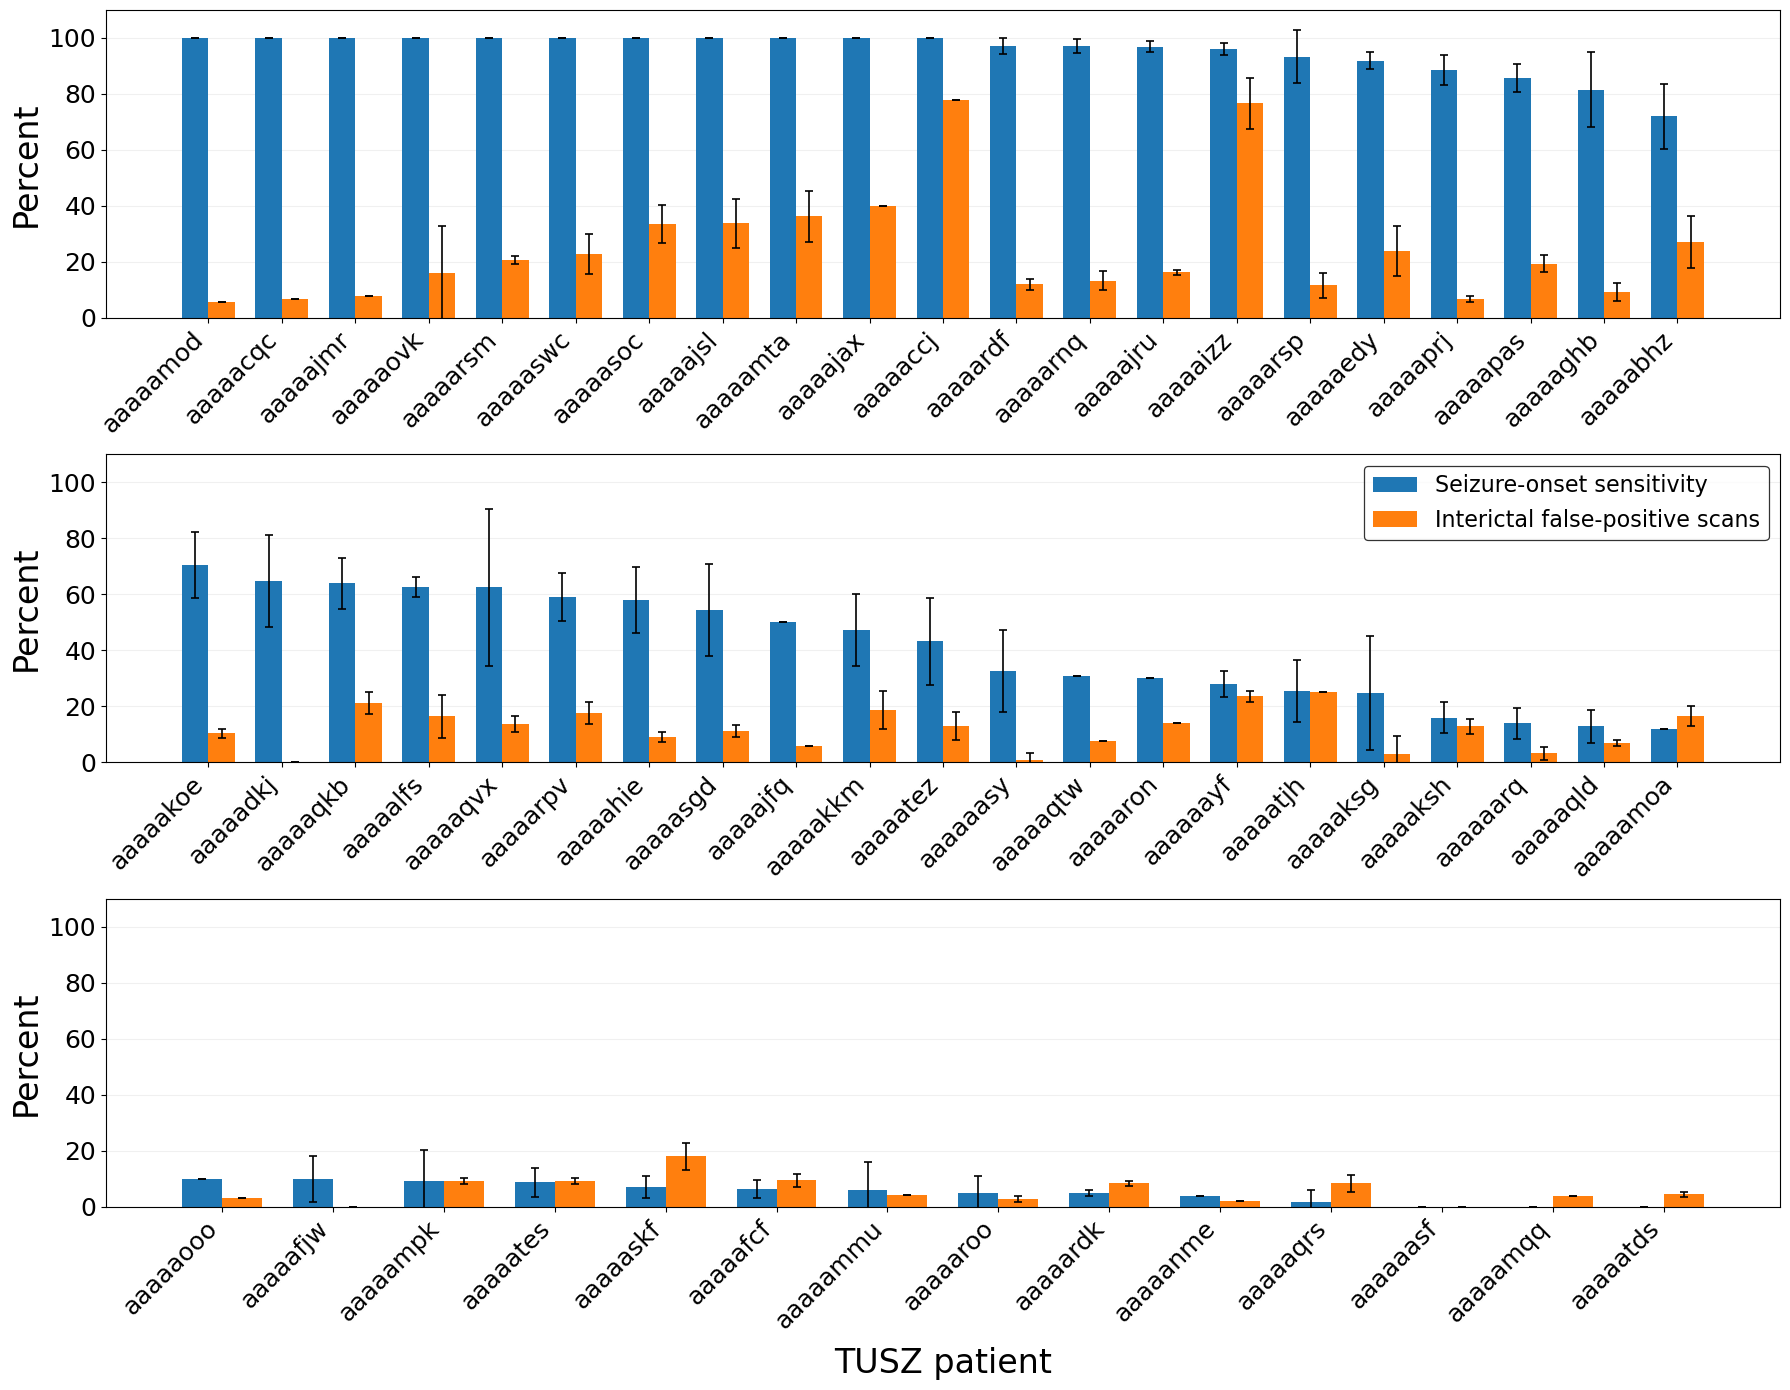

In [7]:
# MAIN FIGURE 1
# Patient-wise seizure-onset sensitivity versus interictal false-positive scan fraction
# with SD error bars across available successful reservoir realizations.

patient_plot = (
    primary.groupby('patient', as_index=False)
    .agg(
        seizure_onset_sensitivity=('ictal_sensitivity', 'mean'),
        seizure_onset_sensitivity_sd=('ictal_sensitivity', 'std'),
        specificity=('specificity', 'mean'),
        specificity_sd=('specificity', 'std'),
        n_successful_seeds=('res_seed', 'nunique'),
    )
)

patient_plot['interictal_fp_fraction'] = 1.0 - patient_plot['specificity']

# Since FP fraction = 1 - specificity, its SD is identical to specificity SD
patient_plot['interictal_fp_fraction_sd'] = patient_plot['specificity_sd']

patient_plot = (
    patient_plot
    .sort_values(
        ['seizure_onset_sensitivity', 'specificity'],
        ascending=[False, False]
    )
    .reset_index(drop=True)
)

panel_slices = [
    slice(0, 21),
    slice(21, 42),
    slice(42, len(patient_plot))
]

fig, axes = plt.subplots(3, 1, figsize=(18, 14), sharey=True)
width = 0.36

for panel_idx, (ax, sl) in enumerate(zip(axes, panel_slices)):

    g = patient_plot.iloc[sl].reset_index(drop=True)
    x = np.arange(len(g))

    sens = 100 * g['seizure_onset_sensitivity'].to_numpy()
    sens_sd = 100 * g['seizure_onset_sensitivity_sd'].fillna(0).to_numpy()

    fp = 100 * g['interictal_fp_fraction'].to_numpy()
    fp_sd = 100 * g['interictal_fp_fraction_sd'].fillna(0).to_numpy()

    ax.bar(
        x - width/2,
        sens,
        width,
        yerr=sens_sd,
        capsize=3,
        error_kw={'elinewidth': 1.2, 'capthick': 1.2},
        label='Seizure-onset sensitivity'
    )

    ax.bar(
        x + width/2,
        fp,
        width,
        yerr=fp_sd,
        capsize=3,
        error_kw={'elinewidth': 1.2, 'capthick': 1.2},
        label='Interictal false-positive scans'
    )

    ax.set_ylim(0, 110)
    ax.set_ylabel('Percent', fontsize=24)

    ax.set_xticks(x)
    ax.set_xticklabels(
        g['patient'],
        rotation=45,
        ha='right',
        fontsize=18
    )

    ax.tick_params(axis='y', labelsize=18)
    ax.grid(axis='y', alpha=0.18, linewidth=0.8)
    ax.set_axisbelow(True)

    if panel_idx == 1:
        leg = ax.legend(
            frameon=True,
            fontsize=16,
            loc='upper right'
        )
        leg.get_frame().set_edgecolor('black')
        leg.get_frame().set_linewidth(0.9)

axes[-1].set_xlabel('TUSZ patient', fontsize=24, labelpad=10)

fig.tight_layout(h_pad=1.2)

for ext in ['png', 'pdf', 'svg']:
    kwargs = {'dpi': FIG_DPI} if ext == 'png' else {}
    fig.savefig(
        FIG_DIR / f'main_tusz_patient_seizure_onset_detection.{ext}',
        bbox_inches='tight',
        **kwargs
    )

plt.show()

## 3. Patient-level secondary performance metrics


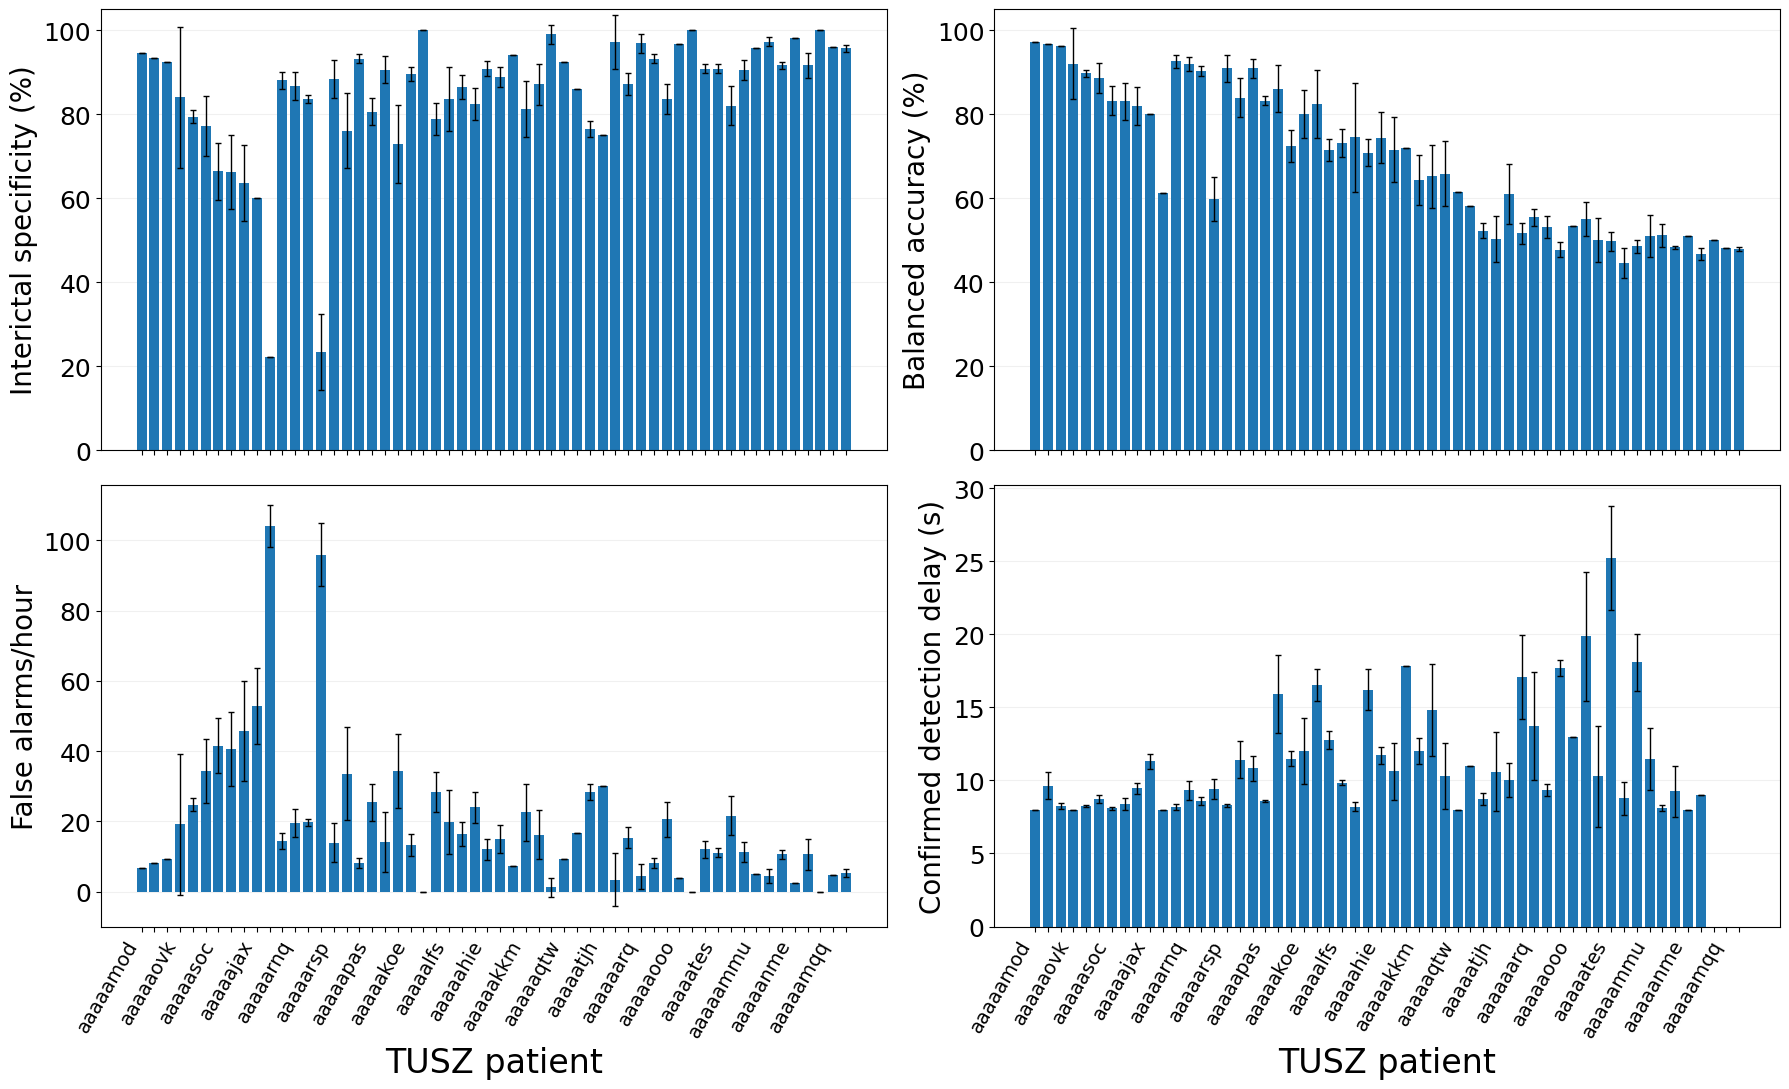

In [9]:
# MAIN FIGURE 2
# Patient-level specificity, balanced accuracy, FAR/hour, and detection delay
# with SD error bars across available successful reservoir realizations.
# Patients remain in exactly the same order as Main Figure 1.

patient_metrics = (
    primary.groupby('patient', as_index=False)
    .agg(
        specificity=('specificity', 'mean'),
        specificity_sd=('specificity', 'std'),

        balanced_accuracy=('balanced_accuracy', 'mean'),
        balanced_accuracy_sd=('balanced_accuracy', 'std'),

        false_alarms_per_hour=('false_alarms_per_hour', 'mean'),
        false_alarms_per_hour_sd=('false_alarms_per_hour', 'std'),

        detection_delay_seconds=('ictal_delay_mean_seconds', 'mean'),
        detection_delay_seconds_sd=('ictal_delay_mean_seconds', 'std'),

        n_successful_seeds=('res_seed', 'nunique'),
    )
)

# Reorder to exactly match Main Figure 1
patient_metrics = (
    patient_primary[['patient']]
    .merge(patient_metrics, on='patient', how='left')
)

x = np.arange(len(patient_metrics))
labels = patient_metrics['patient'].tolist()

show_every = 3
shown_labels = [
    lab if i % show_every == 0 else ''
    for i, lab in enumerate(labels)
]

fig, axes = plt.subplots(2, 2, figsize=(18, 11), sharex=True)

panels = [
    (
        'specificity',
        'specificity_sd',
        'Interictal specificity (%)',
        100.0
    ),
    (
        'balanced_accuracy',
        'balanced_accuracy_sd',
        'Balanced accuracy (%)',
        100.0
    ),
    (
        'false_alarms_per_hour',
        'false_alarms_per_hour_sd',
        'False alarms/hour',
        1.0
    ),
    (
        'detection_delay_seconds',
        'detection_delay_seconds_sd',
        'Confirmed detection delay (s)',
        1.0
    ),
]

for ax, (metric, sd_metric, ylabel, scale) in zip(axes.flat, panels):

    vals = scale * patient_metrics[metric].to_numpy()

    errs = scale * (
        patient_metrics[sd_metric]
        .fillna(0)
        .to_numpy()
    )

    ax.bar(
        x,
        vals,
        width=0.78,
        yerr=errs,
        capsize=2.5,
        error_kw={
            'elinewidth': 1.0,
            'capthick': 1.0
        }
    )

    ax.set_ylabel(ylabel, fontsize=20)
    ax.tick_params(axis='y', labelsize=18)
    ax.grid(axis='y', alpha=0.18, linewidth=0.8)
    ax.set_axisbelow(True)

axes[0, 0].set_ylim(0, 105)
axes[0, 1].set_ylim(0, 105)

for ax in axes[1, :]:
    ax.set_xticks(x)
    ax.set_xticklabels(
        shown_labels,
        rotation=60,
        ha='right',
        fontsize=14
    )
    ax.set_xlabel('TUSZ patient', fontsize=24)

fig.tight_layout(h_pad=1.0, w_pad=1.2)

for ext in ['png', 'pdf', 'svg']:
    kwargs = {'dpi': FIG_DPI} if ext == 'png' else {}

    fig.savefig(
        FIG_DIR / f'main_tusz_patient_secondary_metrics.{ext}',
        bbox_inches='tight',
        **kwargs
    )

plt.show()

## 4. Cohort summary and 3-s versus 5-s persistence


In [10]:
metrics = [
    'seizure_onset_sensitivity',
    'specificity',
    'balanced_accuracy',
    'false_alarms_per_hour',
    'detection_delay_seconds',
]

rows = []
for metric in metrics:
    s = patient_primary[metric].dropna()
    rows.append({
        'metric': metric,
        'n_patients': len(s),
        'mean': s.mean(),
        'sd': s.std(ddof=1),
        'median': s.median(),
        'q25': s.quantile(0.25),
        'q75': s.quantile(0.75),
        'min': s.min(),
        'max': s.max(),
    })

cohort_summary = pd.DataFrame(rows)
display(cohort_summary)
cohort_summary.to_csv(TABLE_DIR / 'tusz_cohort_summary_R4_3s.csv', index=False)


,metric,n_patients,mean,sd,median,q25,q75,min,max
0,seizure_onset_sensitivity,56,0.524308,0.384989,0.560902,0.113235,0.963790,0.000000,1.000000
1,specificity,56,0.847866,0.153040,0.886000,0.810429,0.935000,0.222222,1.000000
2,balanced_accuracy,56,0.686087,0.168102,0.682806,0.514673,0.831498,0.444783,0.972222
3,false_alarms_per_hour,56,19.304283,19.816107,14.258824,7.800000,24.195652,0.000000,104.000000
4,detection_delay_seconds,53,11.290557,3.736426,10.016652,8.584353,12.040558,7.999595,25.208280


In [11]:
pers_patient = (
    valid[valid['regime_id'].astype(int) == EXPECTED_REGIME]
    .groupby(['patient','alarm_persistence_seconds'], as_index=False)
    .agg(
        n_successful_seeds=('res_seed','nunique'),
        seizure_onset_sensitivity=('ictal_sensitivity','mean'),
        specificity=('specificity','mean'),
        balanced_accuracy=('balanced_accuracy','mean'),
        false_alarms_per_hour=('false_alarms_per_hour','mean'),
        detection_delay_seconds=('ictal_delay_mean_seconds','mean'),
    )
)

persistence_summary = (
    pers_patient.groupby('alarm_persistence_seconds', as_index=False)
    .agg(
        n_patients=('patient','nunique'),
        sensitivity_mean=('seizure_onset_sensitivity','mean'),
        sensitivity_sd=('seizure_onset_sensitivity','std'),
        specificity_mean=('specificity','mean'),
        specificity_sd=('specificity','std'),
        ba_mean=('balanced_accuracy','mean'),
        ba_sd=('balanced_accuracy','std'),
        far_mean=('false_alarms_per_hour','mean'),
        far_sd=('false_alarms_per_hour','std'),
        delay_mean=('detection_delay_seconds','mean'),
        delay_sd=('detection_delay_seconds','std'),
        delay_n=('detection_delay_seconds','count'),
    )
)

display(persistence_summary)
persistence_summary.to_csv(TABLE_DIR / 'tusz_persistence_summary_R4.csv', index=False)


,alarm_persistence_seconds,n_patients,sensitivity_mean,sensitivity_sd,specificity_mean,specificity_sd,ba_mean,ba_sd,far_mean,far_sd,delay_mean,delay_sd,delay_n
0,3.0,56,0.524308,0.384989,0.847866,0.153040,0.686087,0.168102,19.304283,19.816107,11.290557,3.736426,53
1,5.0,56,0.492743,0.395527,0.864509,0.143155,0.678626,0.175423,16.875351,18.376461,13.515336,4.287572,53


## Final figure set

For the manuscript, use only:
1. `main_tusz_patient_seizure_onset_detection` — patient-wise external detection and interictal false positives, split across three panels.
2. `main_tusz_patient_secondary_metrics` — specificity, balanced accuracy, FAR/hour, and confirmed detection delay in the same patient order.

The 5-s persistence condition is summarized numerically rather than duplicated as another patient-wise figure.
